### Pobranie grafu OSMnx

In [1]:
import osmnx as ox
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

from pathlib import Path

print("OSMnx:", ox.__version__)
print("NetworkX:", nx.__version__)

OSMnx: 2.1.1
NetworkX: 3.7


In [2]:
# Granice obszaru w układzie WGS84 (EPSG:4326)
# Kolejność: długość geograficzna, szerokość geograficzna

bbox = (
    19.9500,  # zachód
    50.0535,  # południe
    19.9695,  # wschód
    50.0640   # północ
)

In [3]:
G = ox.graph.graph_from_bbox(
    bbox=bbox,
    network_type="bike",
    simplify=True,
    retain_all=True,
    truncate_by_edge=True
)

print("Liczba węzłów:", len(G.nodes))
print("Liczba krawędzi:", len(G.edges))

Liczba węzłów: 796
Liczba krawędzi: 1660


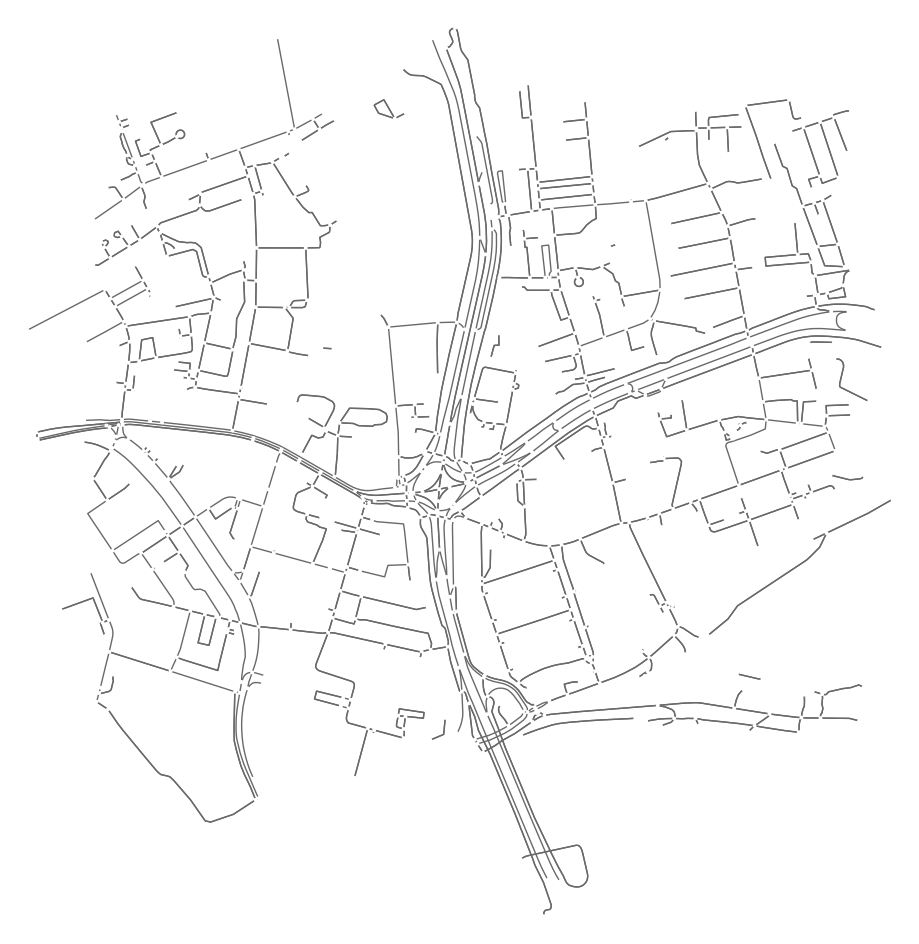

In [4]:
fig, ax = ox.plot_graph(
    G,
    figsize=(12, 12),
    node_size=8,
    edge_linewidth=1,
    edge_color="dimgray",
    bgcolor="white"
)

In [5]:
data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

ox.io.save_graphml(
    G,
    filepath=data_dir / "osm_kotlarska.graphml"
)

### Pobranie danych o infrastrukturze rowerowej z ZTP

In [6]:
import requests
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

In [7]:
# Pobieramy węzły grafu jako GeoDataFrame
nodes_gdf, edges_gdf = ox.convert.graph_to_gdfs(G)

# Upewniamy się, że współrzędne są w układzie WGS84
nodes_gdf = nodes_gdf.to_crs("EPSG:4326")

# Wyznaczamy granice naszego grafu
west, south, east, north = nodes_gdf.total_bounds

print("Granice obszaru:")
print("Zachód:", west)
print("Południe:", south)
print("Wschód:", east)
print("Północ:", north)

Granice obszaru:
Zachód: 19.948042
Południe: 50.050334
Wschód: 19.9710385
Północ: 50.0654971


In [8]:
url = (
    "https://services-eu1.arcgis.com/"
    "svTzSt3AvH7sK6q9/arcgis/rest/services/"
    "Ciagi_rowerowe/FeatureServer/0/query"
)

# Prostokąt obejmujący nasz graf
geometry = {
    "xmin": west,
    "ymin": south,
    "xmax": east,
    "ymax": north
}

params = {
    "where": "1=1",
    "geometry": json.dumps(geometry),
    "geometryType": "esriGeometryEnvelope",
    "inSR": 4326,
    "spatialRel": "esriSpatialRelIntersects",
    "returnIdsOnly": "true",
    "f": "json"
}

response = requests.get(url, params=params)
response.raise_for_status()

result = response.json()

if "error" in result:
    raise RuntimeError(result["error"])

object_ids = result.get("objectIds", [])

print("Liczba obiektów ZTP w naszym obszarze:", len(object_ids))

Liczba obiektów ZTP w naszym obszarze: 92


In [9]:
features = []

# Pobieramy dane partiami po 1000 obiektów
batch_size = 1000

for i in range(0, len(object_ids), batch_size):
    batch_ids = object_ids[i:i + batch_size]

    params = {
        "objectIds": ",".join(map(str, batch_ids)),
        "outFields": "OBJECTID,rodzaj,nawierzchnia",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson"
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])

    features.extend(data.get("features", []))

print("Pobrano geometrii:", len(features))

Pobrano geometrii: 92


In [10]:
ztp_gdf = gpd.GeoDataFrame.from_features(
    features,
    crs="EPSG:4326"
)

print("Liczba obiektów:", len(ztp_gdf))
print("\nDostępne kolumny:")
print(ztp_gdf.columns.tolist())

ztp_gdf.head()

Liczba obiektów: 92

Dostępne kolumny:
['geometry', 'OBJECTID', 'rodzaj', 'nawierzchnia']


,geometry,OBJECTID,rodzaj,nawierzchnia
0,"LINESTRING (19.95789 50.05068, 19.95663 50.050...",5,droga rowerowa,asfalt
1,"LINESTRING (19.93512 50.04989, 19.93521 50.049...",7,droga rowerowa,asfalt
2,"MULTILINESTRING ((19.95851 50.05715, 19.95852 ...",30,droga rowerowa,asfalt
3,"MULTILINESTRING ((19.9581 50.05784, 19.95796 5...",31,droga rowerowa,asfalt
4,"LINESTRING (19.95766 50.06541, 19.9578 50.0653...",32,droga rowerowa,asfalt


In [11]:
data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

ztp_gdf.to_file(
    data_dir / "cycleways_kotlarska.geojson",
    driver="GeoJSON"
)

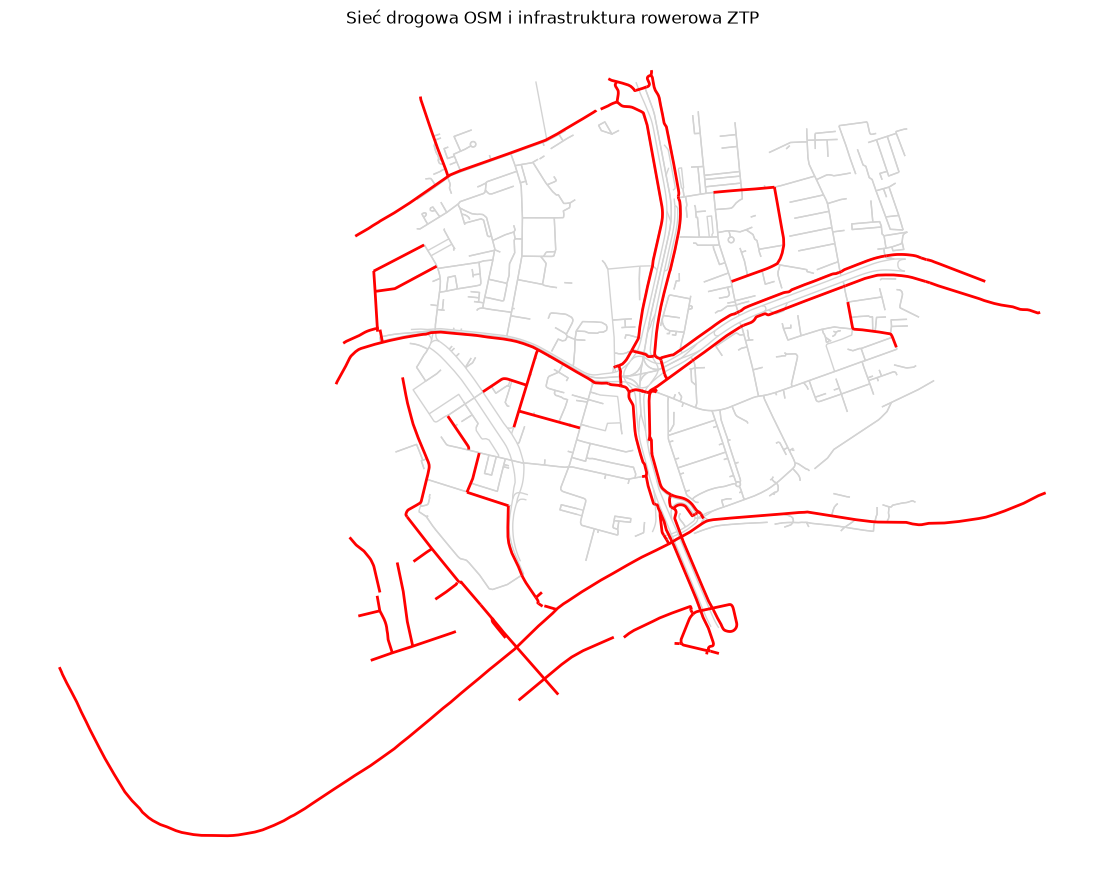

In [13]:
edges_gdf = edges_gdf.to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(14, 14))

# Wszystkie drogi z OSMnx
edges_gdf.plot(
    ax=ax,
    color="lightgray",
    linewidth=1,
    label="Drogi OSM"
)

# Infrastruktura rowerowa ZTP
ztp_gdf.plot(
    ax=ax,
    color="red",
    linewidth=2,
    label="Infrastruktura ZTP"
)

ax.set_title("Sieć drogowa OSM i infrastruktura rowerowa ZTP")
ax.set_axis_off()

plt.show()